# 070 CASE 020 — Wildfire: Kårböle 2018

> **Experimental.** Built in the Swedish Space Data Lab (SDL 3.0) with
> [IMINT Engine](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine). Not a validated product or service, and without support.

**Question:** How large and how severe was the burnt area after the Kårböle fire in summer 2018?

**Area:** Kårböle, Ljusdal municipality (Gävleborg). Before: 2 July 2018. After: 2 September 2018, with its clouds filled from 21 August 2018.

**Partners:** Swedish Forest Agency (Skogsstyrelsen), MSB, RISE

**Data:** Copernicus Sentinel-2 L2A from [Digital Earth Sweden](https://digitalearth.se),
fetched through its openEO API.

**Licence:** The notebook is Apache-2.0 like the repository's code; its saved outputs are CC0 1.0 (see [License](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine#license)). Copernicus Sentinel-2 data are free and open.

## Before you run

Install IMINT Engine at the commit these results were produced with, plus the plotting libraries:

```bash
pip install "imint-engine[fetch,inference] @ git+https://github.com/DigitalEarthSwedenExperimentalLab/imintengine@b183e1a" folium matplotlib
```

The notebook reads Sentinel-2 from Digital Earth Sweden, so each user logs in with their own
DES account in the *Log in* cell below, either with EGI in the browser or with a DES username and
password. The login is yours: no credentials are shared or saved in the notebook. Without a login the data fetch stops with an error; there is no synthetic
fallback, so every figure comes from real Sentinel-2 data. A run takes two to three minutes on a laptop CPU.

## Log in to Digital Earth Sweden

In [ ]:
import os
from getpass import getpass

import openeo

# Log in with your own Digital Earth Sweden account. Choose one:
#   "egi"      - your EGI account in the browser: open the link shown here and enter the code
#   "password" - your DES username and password, typed when asked (never saved in the notebook)
LOGIN_METHOD = "egi"

des = openeo.connect("https://openeo.digitalearth.se")
if LOGIN_METHOD == "password":
    os.environ["DES_USER"] = input("DES username: ")
    os.environ["DES_PASSWORD"] = getpass("DES password: ")
    des.authenticate_basic(os.environ["DES_USER"], os.environ["DES_PASSWORD"])
else:
    des.authenticate_oidc(provider_id="egi")  # rerun this cell when the session expires


def des_token():
    """Your EGI login's access token; with a password login IMINT Engine reads DES_USER/DES_PASSWORD."""
    return des.auth.bearer.split("/", 2)[2] if LOGIN_METHOD == "egi" else None


## 1. Method

```
pre-fire scene ─┐
                ├─ SpectralAnalyzer → NBR (pre), NBR (post) → dNBR = NBR_pre − NBR_post → USGS severity classes
post-fire scene ┘
```

The normalised burn ratio, NBR = (B08 − B12) / (B08 + B12), drops sharply when vegetation burns.
The difference before and after the fire, dNBR, is classed with the USGS thresholds
(0.10 low, 0.27 moderate-low, 0.44 moderate-high, 0.66 high severity). All scenes are snapped
to the same 10 m grid, so they can be combined pixel by pixel. No single date after the fire is
clear over the whole burnt area, so the post-fire NBR takes each pixel from the first listed date
where it is cloud-free.

## 2. Area and data

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import folium

from imint.fetch import fetch_des_data


def load_scene(date, aoi, max_cloud=0.3):
    """Fetch one Sentinel-2 L2A scene from Digital Earth Sweden with your login (no fallback)."""
    scene = fetch_des_data(date=date, coords=aoi, cloud_threshold=max_cloud, token=des_token())
    land = np.isin(scene.scl, [4, 5])  # cloud-free vegetation and bare soil
    if land.any():
        empty = [b for b, a in scene.bands.items() if (a[land] == 0).mean() > 0.05]
        if empty:  # some archived scenes have bands missing; never analyse them
            raise ValueError(f"{date}: bands {empty} are empty over land in this DES scene; use another date")
    h, w = scene.rgb.shape[:2]
    print(f"{date}: {len(scene.bands)} bands, {h} x {w} px at 10 m, "
          f"cloud {scene.cloud_fraction:.1%} (SCL), CRS {scene.geo.crs}")
    return scene


def true_colour(scene, top=0.25):
    """True colour with a fixed stretch, so different dates are comparable."""
    return np.clip(np.dstack([scene.bands[b] for b in ("B04", "B03", "B02")]) / top, 0, 1)

AOI = {"west": 15.15, "south": 61.84, "east": 15.60, "north": 62.06}  # the Kårböle burn scar
PRE_FIRE = "2018-07-02"
POST_FIRE = ["2018-09-02", "2018-08-21"]  # clouds in the first are filled from the second

pre = load_scene(PRE_FIRE, AOI)
posts = [load_scene(date, AOI, max_cloud=0.5) for date in POST_FIRE]

    [DES] openEO api=1.1.0 url=https://openeo.digitalearth.se/


    Cloud fraction: 0.0%


2018-07-02: 11 bands, 2465 x 2376 px at 10 m, cloud 0.0% (SCL), CRS EPSG:3006
    [DES] openEO api=1.1.0 url=https://openeo.digitalearth.se/


    Cloud fraction: 48.2%


2018-09-02: 11 bands, 2465 x 2376 px at 10 m, cloud 48.2% (SCL), CRS EPSG:3006
    [DES] openEO api=1.1.0 url=https://openeo.digitalearth.se/


    Cloud fraction: 32.5%


2018-08-21: 11 bands, 2465 x 2376 px at 10 m, cloud 32.5% (SCL), CRS EPSG:3006


In [3]:
center = [(AOI["south"] + AOI["north"]) / 2, (AOI["west"] + AOI["east"]) / 2]
m = folium.Map(location=center, zoom_start=10, tiles="OpenStreetMap")
folium.TileLayer(
    tiles="https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}",
    attr="Esri, Maxar, Earthstar Geographics", name="Satellite basemap",
).add_to(m)
folium.Rectangle(
    bounds=[[AOI["south"], AOI["west"]], [AOI["north"], AOI["east"]]],
    color="#d73a49", weight=2, fill=False, popup="Kårböle fire 2018",
).add_to(m)
folium.LayerControl().add_to(m)
m

## 3. dNBR and burn severity

In [4]:
from imint.analyzers.spectral import SpectralAnalyzer

def nbr(scene, date):
    res = SpectralAnalyzer().run(rgb=scene.rgb, bands=scene.bands, date=date, coords=AOI,
                                 output_dir="outputs/020", scl=scene.scl, geo=scene.geo)
    print(res.summary())
    return res.outputs["indices"]["NBR"]

CLOUD = [3, 8, 9, 10]  # SCL: cloud shadow, cloud medium/high probability, cirrus
nbr_pre = nbr(pre, PRE_FIRE)
nbr_post = np.full(nbr_pre.shape, np.nan)
for scene, date in zip(posts, POST_FIRE):
    values = nbr(scene, date)
    assert values.shape == nbr_pre.shape, "scenes are not on the same grid"
    fill = np.isnan(nbr_post) & ~np.isin(scene.scl, CLOUD)
    nbr_post[fill] = values[fill]
    print(f"  {date}: {fill.mean():.1%} of the area taken from this date")
dnbr = np.where(np.isin(pre.scl, CLOUD), np.nan, nbr_pre - nbr_post)

valid = ~np.isnan(dnbr)
pixel_ha = 0.01  # one 10 m pixel = 0.01 ha
classes = [("unburnt or regrowth", -np.inf, 0.10), ("low", 0.10, 0.27),
           ("moderate-low", 0.27, 0.44), ("moderate-high", 0.44, 0.66), ("high", 0.66, np.inf)]
print(f"valid pixels: {valid.mean():.1%} of the area")
for name, lo, hi in classes:
    n = int(((dnbr >= lo) & (dnbr < hi)).sum())
    print(f"  {name:20s} {n * pixel_ha:9.0f} ha  ({n / valid.sum():.1%})")
burnt_ha = float((dnbr >= 0.27).sum() * pixel_ha)
print(f"burnt at moderate severity or worse (dNBR ≥ 0.27): {burnt_ha:,.0f} ha")

[spectral] OK — outputs: indices


[spectral] OK — outputs: indices
  2018-09-02: 51.8% of the area taken from this date
[spectral] OK — outputs: indices


  2018-08-21: 34.3% of the area taken from this date
valid pixels: 86.1% of the area
  unburnt or regrowth      40869 ha  (81.1%)
  low                       3484 ha  (6.9%)
  moderate-low              2567 ha  (5.1%)


  moderate-high             2193 ha  (4.3%)
  high                      1312 ha  (2.6%)
burnt at moderate severity or worse (dNBR ≥ 0.27): 6,072 ha


## 4. Results

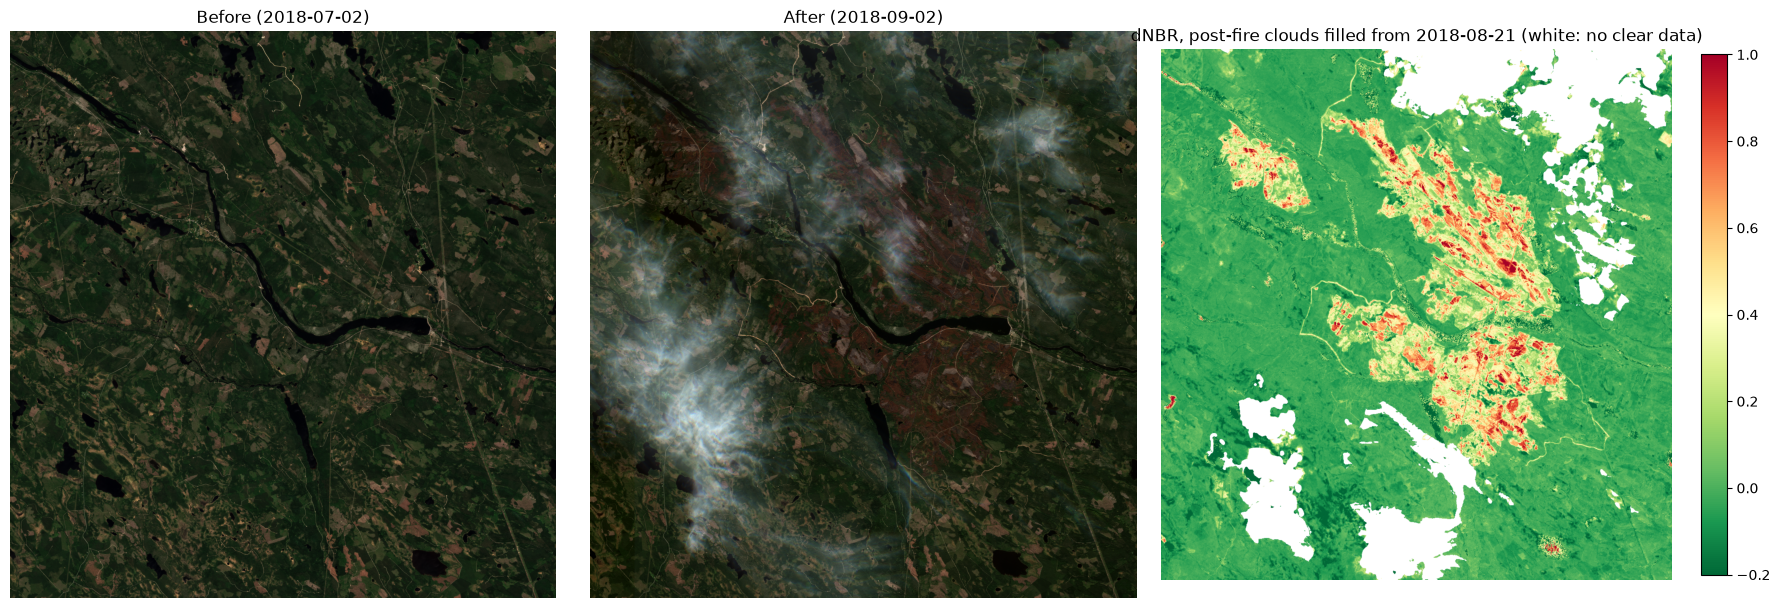

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
axes[0].imshow(true_colour(pre)); axes[0].set_title(f"Before ({PRE_FIRE})")
axes[1].imshow(true_colour(posts[0])); axes[1].set_title(f"After ({POST_FIRE[0]})")
im = axes[2].imshow(dnbr, cmap="RdYlGn_r", vmin=-0.2, vmax=1.0)
axes[2].set_title("dNBR, post-fire clouds filled from " + " and ".join(POST_FIRE[1:]) + " (white: no clear data)")
fig.colorbar(im, ax=axes[2], fraction=0.046)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 5. Interpretation

The burnt area stands out as a coherent patch of high dNBR. The area figure depends on the
threshold: the USGS classes were calibrated on North American forests and are a starting point,
not a Swedish standard. Clouds and shadows in either scene are masked and counted as unknown.

**Next steps:** compare with the Swedish Forest Agency's mapped fire perimeter, add a scene from
2019 to follow regrowth, or run the `prithvi` analyzer with the IBM/NASA burn-scar head
(`task_head: burn_scars`) for an AI segmentation; it needs a GPU for areas this size.

**Links:** [`imint/analyzers/spectral.py`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/blob/b183e1a/imint/analyzers/spectral.py)

## Provenance

The saved outputs were produced by running this notebook top to bottom against IMINT Engine commit [`b183e1a`](https://github.com/DigitalEarthSwedenExperimentalLab/imintengine/commit/b183e1abd4653cb843a75557b05c09915fb85904) with data from Digital Earth Sweden. Dates are acquisition dates, chosen among the scenes DES holds by the cloud fraction over the area in the scene classification (SCL).